# MARL-BattleGrounds Walkthrough

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arm-2-lab/MARL-BattleGrounds/blob/main/examples/quickstart.ipynb)

MARL-BattleGrounds (MARL-BGs) is a JAX-native benchmark for team-vs-team multi-agent reinforcement learning: two teams of up to five agents (Mage, Warrior, Hunter, Rogue and Priest) fight on 52 maps. This notebook walks through it in four parts:

1. The API: make a batch of games, play them and watch one.
2. Speed: how many game steps per second this GPU plays.
3. Training: train a team in a short run (the cell prints its time), and see how a released team learned over 250 million steps.
4. The trained Season 0 teams: load them from Hugging Face by name and play against them.

⚠️ Check that a GPU is selected: Runtime > Change runtime type > T4 GPU ⚠️

The BattleClient (play against the trained teams) and the Replay Viewer (step through any game) run on your own computer, not in Colab: https://marl-battlegrounds.com/#start.

### Install Dependencies 📚

The next cell installs MARL-BattleGrounds with the JAX build for this GPU. Then it restarts the runtime once by itself: Colab says the session crashed, which is expected. Then click Runtime > Run all again; the cell then sees the package and carries on.

Expected and harmless: red "dependency resolver" lines from pip (Colab's own packages want older versions of some libraries), and a Hugging Face warning about unauthenticated requests (no account or token is needed).

In [1]:
# In Colab: install MARL-BattleGrounds with the JAX build for this runtime,
# then restart the runtime once. Anywhere else this cell does nothing; install
# first with https://marl-battlegrounds.com/#start.
import importlib.metadata
import subprocess
import sys

VERSION = "1.0.2"

if "google.colab" in sys.modules:
    try:
        installed = importlib.metadata.version("marl-battlegrounds")
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed == VERSION:
        print(f"MARL-BattleGrounds {VERSION} is installed. Carry on.")
    else:
        names = {
            (d.metadata["Name"] or "").lower()
            for d in importlib.metadata.distributions()
        }
        builds = (
            ("jax-cuda13-plugin", "cuda13"),
            ("jax-cuda12-plugin", "cuda12"),
            ("libtpu", "tpu"),
        )
        build = next((choice for plugin, choice in builds if plugin in names), None)
        extras = "all" if build is None else f"all,{build}"
        package = f"marl-battlegrounds[{extras}]=={VERSION}"
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", package], check=True
        )
        print(f"Installed {package}. Restarting the runtime now.")
        print("When it is back, click Runtime > Run all again.")
        exit(0)  # restarts the runtime, so JAX loads the new build

## Part 1: The MARL-BGs API 🕹️

MARL-BGs works like other JAX environments, such as JaxMARL's:

- `marl_bgs.make("tdm", map_id=6, num_envs=128)` makes a batch of 128 Team Deathmatch games on one map. Maps 0-11 are a curriculum, 0-41 are for training, 42-46 for validation and 47-51 for testing.
- `obs, state = env.reset(key)` starts every game. `state` holds everything; `obs` holds what each agent may see.
- `env.sample_actions(key, state)` gives random legal actions for all ten agents of every game.
- `obs, state, reward, done, info = env.step(key, state, actions)` plays one tick of every game. `reward.rewards` holds each agent's reward, shape (games, 10); `done.done` says which games ended; `info` holds extra facts about each game.
- `obs, state = env.reset_done(key, state)` restarts only the games that ended.

Agents 0-4 are Team A and agents 5-9 are Team B. Everything compiles with `jax.jit`, and works inside `jax.vmap` and `jax.lax.scan`.

In [2]:
import time

import jax
import numpy as np

import marl_battlegrounds as marl_bgs

GPU = jax.default_backend() == "gpu"
print("JAX runs on:", jax.devices())
if not GPU:
    print("No GPU found, so Parts 2 and 3 use small settings.")
    print("In Colab: Runtime > Change runtime type > T4 GPU, then run all again.")

GAMES = 128 if GPU else 16  # games at once; fewer without a GPU
env = marl_bgs.make("tdm", map_id=6, num_envs=GAMES)  # map 6: walls and pillars
key = jax.random.key(0)
key, reset_key = jax.random.split(key)
obs, state = env.reset(reset_key)
roster = env.agent_info(state)  # each agent's class and team, for drawing

frames = []  # game 0 at every tick until it ends: positions and who is alive
start = time.perf_counter()
for tick in range(150):
    key, action_key, step_key, reset_key = jax.random.split(key, 4)
    actions = env.sample_actions(action_key, state)
    obs, state, reward, done, info = env.step(step_key, state, actions)
    if len(frames) == tick:  # still recording game 0
        frames.append(
            (
                np.asarray(state.core_state.agent_positions[0]),
                np.asarray(state.core_state.alive_mask[0]),
            )
        )
        if bool(np.asarray(done.done)[0]):
            frames.append(frames[-1])
    obs, state = env.reset_done(reset_key, state)
jax.block_until_ready(state)
seconds = time.perf_counter() - start
print(
    f"Played 150 ticks of {GAMES} games at once in {seconds:.1f} s, compiling included."
)

JAX runs on: [CudaDevice(id=0)]


Played 150 ticks of 128 games at once in 8.9 s, compiling included.


Watch game 0: each letter is an agent (M Mage, W Warrior, H Hunter, R Rogue, P Priest), blue is Team A and red is Team B, and fallen agents fade. Gray shapes are walls and pillars: they block sight and attacks. Random legal play is not clever, but it fights.

In [3]:
import matplotlib.pyplot as plt
from IPython.display import HTML
from matplotlib import animation, patches

LETTERS = " MWHRP"  # class ids 1-5: Mage, Warrior, Hunter, Rogue, Priest
teams = np.asarray(roster["team_ids"][0])
classes = np.asarray(roster["class_ids"][0])
active = np.asarray(roster["active_mask"][0])
colors = np.where(teams == 1, "tab:blue", "tab:red")  # team 1 is Team A

fig, ax = plt.subplots(figsize=(8, 4), dpi=72)
ax.set_xlim(0, 20)
ax.set_ylim(0, 10)
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])
for kind, x, y, radius, width, height, theta, on in np.asarray(
    state.config.obstacles[0]
):
    if on and kind == 1:
        ax.add_patch(patches.Circle((x, y), radius, color="0.6"))
    elif on and kind == 2:
        ax.add_patch(
            patches.Rectangle(
                (x - width / 2, y - height / 2),
                width,
                height,
                angle=float(np.degrees(theta)),
                rotation_point="center",
                color="0.6",
            )
        )
labels = [
    ax.text(
        0,
        0,
        LETTERS[c],
        color="white",
        ha="center",
        va="center",
        fontweight="bold",
        bbox={"boxstyle": "circle", "facecolor": colors[i], "edgecolor": "none"},
    )
    for i, c in enumerate(classes)
]


def draw(frame: int) -> list:
    positions, alive = frames[frame]
    for i, label in enumerate(labels):
        label.set_position(positions[i])
        label.set_alpha(1.0 if alive[i] else 0.25)
        label.set_visible(bool(active[i]))
    ax.set_title(f"Game 0, tick {frame}")
    return labels


movie = animation.FuncAnimation(fig, draw, frames=len(frames), interval=100)
plt.close(fig)
HTML(movie.to_jshtml())

## Part 2: Compare Speed 🚀

How many game steps per second does this GPU play? One game step is one tick of one game, with all ten agents acting. `simulator_speed` plays random legal games on test map 47 and times the warm calls, compilation excluded. More games at once keep the GPU busier, until it is full.

For comparison: the same JAX game, two games at a time, on this machine's CPU; and the numbers we measured on an NVIDIA RTX 5090 (500 ticks per call, median of 5 warm calls).

Measured in 67 s.
   32 games on NVIDIA GeForce RTX 5090:     5,114 game steps per second
  128 games on NVIDIA GeForce RTX 5090:    17,868 game steps per second
  512 games on NVIDIA GeForce RTX 5090:    40,975 game steps per second
 1024 games on NVIDIA GeForce RTX 5090:    51,031 game steps per second
    2 games on the CPU:       110 game steps per second


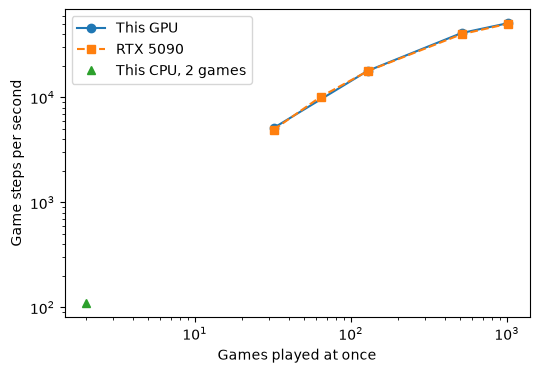

In [4]:
from IPython.display import display

from marl_battlegrounds.experiments.speed import simulator_speed

RTX_5090 = {
    32: 4919,
    64: 10122,
    128: 17760,
    512: 39921,
    1024: 50416,
}  # game steps per second
sizes = [32, 128, 512, 1024] if GPU else [32]
start = time.perf_counter()
speed = {
    n: simulator_speed(n, map_id=47, steps=100, repeats=3, seed=0)[
        "game_steps_per_second"
    ]
    for n in sizes
}
with jax.default_device(jax.devices("cpu")[0]):
    cpu_speed = simulator_speed(2, map_id=47, steps=100, repeats=3, seed=0)[
        "game_steps_per_second"
    ]
print(f"Measured in {time.perf_counter() - start:.0f} s.")
device = jax.devices()[0].device_kind
for n, value in speed.items():
    print(f"{n:5d} games on {device}: {value:9,.0f} game steps per second")
print(f"    2 games on the CPU: {cpu_speed:9,.0f} game steps per second")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(
    list(speed), list(speed.values()), "o-", label=f"This {'GPU' if GPU else 'machine'}"
)
ax.plot(list(RTX_5090), list(RTX_5090.values()), "s--", label="RTX 5090")
ax.plot([2], [cpu_speed], "^", label="This CPU, 2 games")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Games played at once")
ax.set_ylabel("Game steps per second")
ax.legend()
display(fig)
plt.close(fig)

## Part 3: Train a Team ⚔️

Train a Recurrent MAPPO team with MARL-BGs' own trainer, using the same settings as the released Recurrent MAPPO team (its Hydra recipe), except for a short budget, a random opponent and quick checks: one at the start and four more as it trains (two without a GPU). Each check plays the team against the random team on the validation maps and records the point margin: points for minus points against, per game. A rising margin means the team is learning.

JaxMARL's walkthrough trains three seeds at once with `jax.vmap`; MARL-BGs' trainer runs one seed per run and saves checkpoints, checks and records as it goes. The same run from the command line: `python -m marl_battlegrounds.experiments.train method=mappo opponents='{random: 1.0}' ...`.

In [5]:
import os
import tempfile

from hydra import compose, initialize_config_module

from marl_battlegrounds import training
from marl_battlegrounds.experiments.hydra import resolve_training_config

BUDGET = (
    1_015_808 if GPU else 16_384
)  # training steps (env steps); the released team trained for 250,675,200
run_dir = tempfile.mkdtemp(
    prefix="walkthrough-run-"
)  # a new folder each time, so Run all works twice
overrides = [
    "method=mappo",
    f"total_env_steps={BUDGET}",
    "opponents={random: 1.0}",
    "keep_past=0",
    "past_capture_interval=null",
    "validation_opponents=[random]",
    "routine_seed_pairs=1",
    "confirmation_seed_pairs=1",
    "validation_fractions=" + ("[0.25,0.5,0.75,1.0]" if GPU else "[0.5,1.0]"),
    "retain_all_actors=false",
    "verbose=false",
]
if not GPU:
    overrides.append("num_envs=32")
with initialize_config_module(
    version_base="1.3", config_module="marl_battlegrounds.experiments.configs"
):
    settings = compose(config_name="train", overrides=overrides)
config = resolve_training_config(settings, base_dir=os.getcwd())
print(f"Training {BUDGET:,} steps on {jax.devices()[0].device_kind}.")
print("This cell prints how long it took.")
start = time.perf_counter()
run = training.train(config, output_dir=run_dir)
print(f"Trained {BUDGET:,} steps in {(time.perf_counter() - start) / 60:.1f} minutes.")
trained_team = training.load_system(
    run.selected_actor or run.final_actor
)  # the saved team, ready to play

Training 1,015,808 steps on NVIDIA GeForce RTX 5090.
This cell prints how long it took.


Trained 1,015,808 steps in 2.5 minutes.


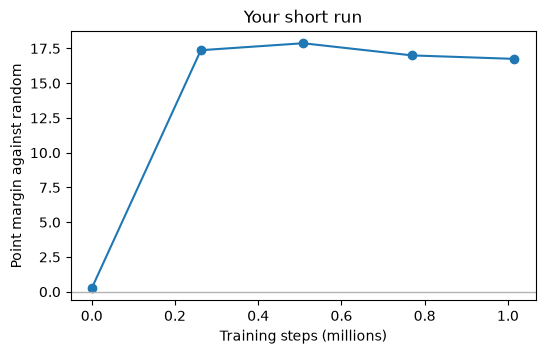

In [6]:
checks = training.list_runs(run_dir, progress=True)[0]["progress"]["checks"]
steps = [check["env_steps"] / 1e6 for check in checks]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(steps, [check["margin"] for check in checks], "o-")
ax.axhline(0, color="0.7", lw=1)
ax.set_xlabel("Training steps (millions)")
ax.set_ylabel("Point margin against random")
ax.set_title("Your short run")
display(fig)
plt.close(fig)

This short run shows training working. For learning over a whole run, here is the released Recurrent MAPPO team's curve: its 31 checks from 0 to 250 million steps, each against a fixed panel (a trained Recurrent MAPPO team and TDM-Alpha, Beta and Gamma, 128 games per check). The dotted line at 40 million steps is where the run was continued. Its records download from Hugging Face. It trained against itself, its past saves, TDM-Alpha, TDM-Beta and six earlier Recurrent MAPPO teams, so its numbers do not compare with your run's margin against random.

/tmp/walkthrough-curves-x4xrdbbr/summary.md
Drawn in 4 s.


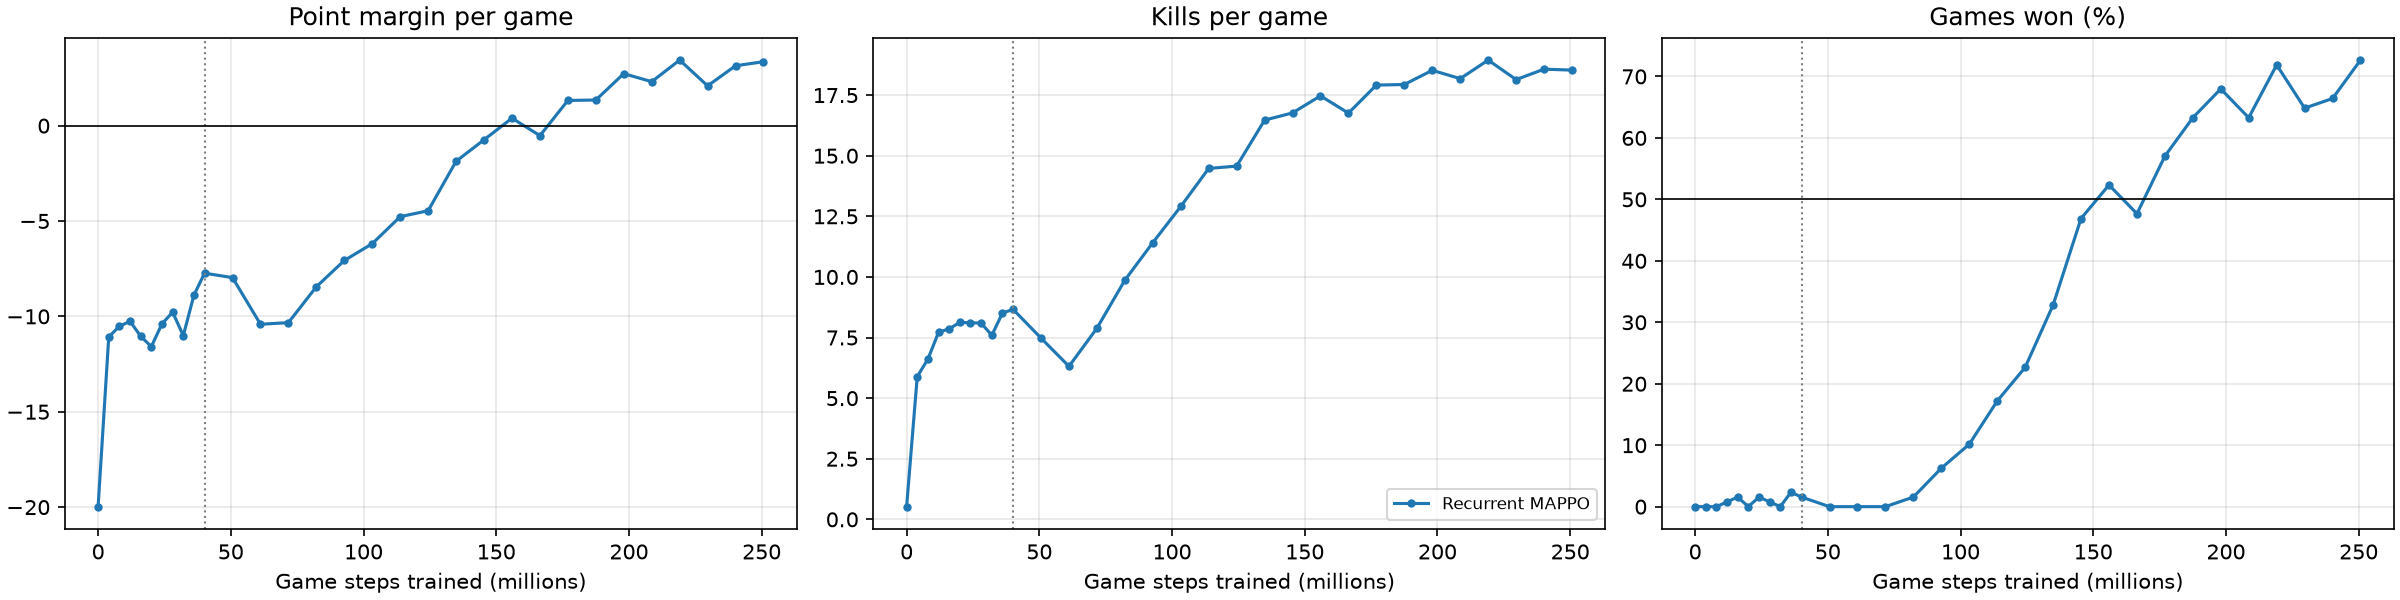

In [7]:
import subprocess
import sys

from IPython.display import Image

curves_dir = tempfile.mkdtemp(prefix="walkthrough-curves-")
lineage = (
    "lineages=[{name: Recurrent MAPPO, "
    "repo: MARL-BattleGrounds/tdm-season-0-recurrent-mappo}]"
)
start = time.perf_counter()
# In a terminal: python -m marl_battlegrounds.experiments.training_curves ...
subprocess.run(
    [
        sys.executable,
        "-m",
        "marl_battlegrounds.experiments.training_curves",
        lineage,
        f"output_dir={curves_dir}",
        "hydra/job_logging=disabled",
    ],
    check=True,
    env={**os.environ, "HF_HUB_DISABLE_PROGRESS_BARS": "1"},
)
print(f"Drawn in {time.perf_counter() - start:.0f} s.")
Image(filename=os.path.join(curves_dir, "curves.png"))

## Part 4: The Trained Season 0 Teams 🤗

The six Season 0 models are on Hugging Face, with a file for every save from the start of training to 250 million steps. Write a model's name anywhere MARL-BGs takes a model, and add `@` to pick a save: `@final` is the last save, `@100M` is the nearest save at or before 100 million steps, and an exact step such as `@99_942_400` (a save of the model below) is that save. Each file downloads once and is checked before use. No account or token is needed, so Hugging Face's warning about unauthenticated requests is harmless.

First, the Season 0 winner, Recurrent IPPO, at its last save. It plays 32 games (10 without a GPU) against the built-in TDM-Alpha team on the five test maps, as Team A in every game; paired games swap the two spawn ends.

In [8]:
import time

import pandas as pd
from IPython.display import display


def team_a_rows(games: marl_bgs.EvaluationResult, by: str = "overall") -> pd.DataFrame:
    """Return your team's rows of the head-to-head table, overall or by map."""
    team_a = games.metadata["system_ids"]["team_a"]
    table = pd.DataFrame(games.head_to_head(by=by))
    shown = ["map_id"] if by == "map" else []
    shown += ["system_name", "opponent_name", "games", "wins", "draws", "losses"]
    shown += ["mean_point_margin"]
    return table[table["system_id"] == team_a][shown]


start = time.perf_counter()
GAMES = 32 if GPU else 10  # fewer games without a GPU
WINNER = "MARL-BattleGrounds/tdm-season-0-recurrent-ippo"
saves = {"@final": marl_bgs.load_method(f"{WINNER}@final")}
results = {
    "@final": marl_bgs.evaluate(
        saves["@final"], "tdm-alpha", num_episodes=GAMES, seed=0, num_envs=GAMES
    )
}
display(team_a_rows(results["@final"]))
display(team_a_rows(results["@final"], by="map"))
print(f"Took {time.perf_counter() - start:.0f} s")

,system_name,opponent_name,games,wins,draws,losses,mean_point_margin
0,"IPPO at step 250,675,200 (run)",tdm-alpha,32,29,0,3,7.1875


,map_id,system_name,opponent_name,games,wins,draws,losses,mean_point_margin
0,47,"IPPO at step 250,675,200 (run)",tdm-alpha,8,5,0,3,3.000000
1,48,"IPPO at step 250,675,200 (run)",tdm-alpha,6,6,0,0,6.833333
2,49,"IPPO at step 250,675,200 (run)",tdm-alpha,6,6,0,0,6.666667
3,50,"IPPO at step 250,675,200 (run)",tdm-alpha,6,6,0,0,9.000000
4,51,"IPPO at step 250,675,200 (run)",tdm-alpha,6,6,0,0,11.833333


Took 16 s


### Watch the Winner Learn

The same model at 10 million and at 100 million steps plays the same games. The table and the chart show, for each save, its wins, draws and losses, and per game its point margin (points for minus points against), kills and deaths. The early save loses most of its games to TDM-Alpha; the last save wins most of them.

,wins,draws,losses,point margin,kills,deaths
@10M,0.0,0.0,32.0,-11.09,8.22,19.75
@100M,20.0,0.0,12.0,0.09,17.62,15.47
@final,29.0,0.0,3.0,7.19,19.59,11.31


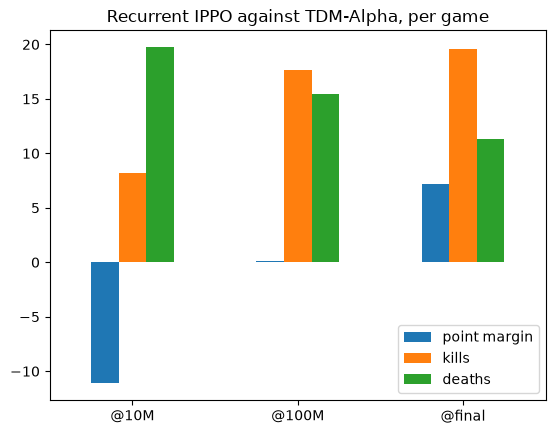

Took 6 s


In [9]:
start = time.perf_counter()
for save in ("@10M", "@100M"):
    saves[save] = marl_bgs.load_method(f"{WINNER}{save}")
    results[save] = marl_bgs.evaluate(
        saves[save], "tdm-alpha", num_episodes=GAMES, seed=0, num_envs=GAMES
    )


def ladder_row(games: marl_bgs.EvaluationResult) -> dict[str, float]:
    """Return Team A's wins, draws, losses, point margin, kills and deaths."""
    row = team_a_rows(games).iloc[0]
    metrics = pd.DataFrame(games.priority_metrics)
    return {
        "wins": row["wins"],
        "draws": row["draws"],
        "losses": row["losses"],
        "point margin": row["mean_point_margin"],
        "kills": metrics["team_a_kills"].mean(),
        "deaths": metrics["team_a_deaths"].mean(),
    }


ladder = pd.DataFrame(
    {save: ladder_row(results[save]) for save in ("@10M", "@100M", "@final")}
).T
display(ladder.round(2))
axis = ladder[["point margin", "kills", "deaths"]].plot.bar(
    rot=0, title="Recurrent IPPO against TDM-Alpha, per game"
)
display(axis.figure)
plt.close(axis.figure)
print(f"Took {time.perf_counter() - start:.0f} s")

### Optional: Your Team on the Ladder

Your Part 3 team plays the same games against each of the three saves. This is a quick yardstick on this machine, not a leaderboard result: official leaderboard runs are made by the maintainers from a submission.

In [10]:
start = time.perf_counter()
your_team = trained_team  # the team you trained in Part 3
yardstick = {}
for save in ("@10M", "@100M", "@final"):
    games = marl_bgs.evaluate(
        your_team, saves[save], num_episodes=GAMES, seed=0, num_envs=GAMES
    )
    yardstick[f"against {save}"] = ladder_row(games)
display(pd.DataFrame(yardstick).T.round(2))
print(f"Took {time.perf_counter() - start:.0f} s")

,wins,draws,losses,point margin,kills,deaths
against @10M,0.0,32.0,0.0,-2.56,2.03,3.50
against @100M,0.0,30.0,2.0,-7.59,2.78,9.78
against @final,0.0,31.0,1.0,-9.78,1.00,9.47


Took 15 s


## Next

- See the paper's analysis of all 7,200 Season 0 games, with every chart, in [the analysis notebook](https://colab.research.google.com/github/arm-2-lab/MARL-BattleGrounds/blob/main/examples/evaluate/evaluation_analysis.ipynb).
- Install on your own computer to play in the BattleClient and step through replays: https://marl-battlegrounds.com/#start.
- Train your own team: [the training guide](https://github.com/arm-2-lab/MARL-BattleGrounds/blob/main/docs/training.md).
- The trained Season 0 teams and every save: [MARL-BattleGrounds on Hugging Face](https://huggingface.co/MARL-BattleGrounds).